# Partner-distance decoding — end-to-end demo

Decode the continuous Euclidean distance between a focal (implanted) animal and a
*specific* partner from the focal's neural activity, using regression
([`analysis/partner_distance/decode_partner_distance.py`](decode_partner_distance.py)).

Walks through:

1. Synthetic, ephys-aligned arrays (so the notebook runs offline).
2. Population decode — cross-validated R² / RMSE, plus the **partial R²** that
   removes the focal animal's own speed + position (the self-motion confound).
3. Single-cell scores — per-cell R², Pearson r, partial R², and the ranked
   "distance cells", plus 1-D distance tuning curves.
3b. **Where linear ridge breaks down** — bump-shaped distance tuning, the
   robust **pooled** R² / per-fold diagnostics, and a **Bayesian** decoder over
   the tuning curves (`decoder="both"`).
4. A circular-shift **null** for significance.
5. All plots (including the diagnostics + Bayesian posterior panels).
6. A drop-in **real-data variant** via `decode_partner_distance(session_id, focal, partner, ...)`.

The math is whole-session, time-binned: firing rates and distance are binned on
one common ephys-second grid and regressed with contiguous-block CV (no
shuffling) because both signals are strongly autocorrelated.

In [ ]:
import sys
from pathlib import Path

# Make sibling modules importable from the notebook's location (ephys/).
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import matplotlib.pyplot as plt

from analysis.partner_distance.decode_partner_distance import (
    _analyze,
    single_cell_distance_scores,
    population_distance_regression,
    compute_distance_tuning,
)
from analysis.partner_distance.decode_partner_distance_plots import (
    plot_distance_tuning_curves,
    plot_per_cell_r2_distribution,
    plot_predicted_vs_actual_scatter,
    plot_predicted_vs_actual_timeseries,
    plot_partner_distance_summary,
    plot_regression_diagnostics,
    plot_distance_posterior,
)

## 0. Synthetic, ephys-aligned arrays

These mirror exactly what `build_distance_binned_data` returns from real
`KilosortData` + `VideoTrackingData`:

- `firing_rates` — `(n_bins, n_cells)` Hz,
- `distance` — `(n_bins,)` focal-partner distance (here in cm),
- `nuisance` — `(n_bins, 3)` focal self-motion `[speed, x, y]`,
- `bin_centers` — `(n_bins,)` ephys seconds.

Partner distance is a mean-reverting (Ornstein-Uhlenbeck) process — bounded and
autocorrelated, like a real arena distance. We plant **two genuine distance
cells**, **one self-motion ("confound") cell** that tracks the focal's own speed
(which is itself correlated with distance), and a bank of **noise cells**.

In [7]:
rng = np.random.default_rng(0)
T = 2000
bin_size_sec = 0.5
bin_centers = np.arange(T) * bin_size_sec

# --- Mean-reverting partner distance (OU process), in cm ----------------------
theta, mu, sigma = 0.02, 60.0, 3.0
d = np.empty(T); d[0] = mu
for t in range(1, T):
    d[t] = d[t-1] + theta * (mu - d[t-1]) + sigma * rng.standard_normal()
distance = np.abs(d)
dz = (distance - distance.mean()) / distance.std()

# --- Focal self-motion (the confound): correlated with distance ---------------
focal_speed = 0.7 * dz + 0.5 * rng.standard_normal(T)
focal_x = np.cumsum(0.3 * rng.standard_normal(T))   # arbitrary position columns
focal_y = np.cumsum(0.3 * rng.standard_normal(T))
nuisance = np.column_stack([focal_speed, focal_x, focal_y])
nuisance_names = ["focal_speed", "focal_x", "focal_y"]

# --- Cells (baseline + signal), clipped to look like Hz -----------------------
base = 5.0
c_dist_pos  =  1.0 * dz + 0.40 * rng.standard_normal(T)   # genuine distance cell (+)
c_dist_neg  = -0.8 * dz + 0.50 * rng.standard_normal(T)   # genuine distance cell (-)
c_selfmotion = focal_speed + 0.10 * rng.standard_normal(T)  # encodes self-motion only
noise_cells = rng.standard_normal((T, 12))

firing_rates = np.clip(
    base + np.column_stack([c_dist_pos, c_dist_neg, c_selfmotion, noise_cells]),
    0.0, None,
)
cell_labels = ["dist+ (0)", "dist- (1)", "self-motion (2)"] + \
              [f"noise ({i})" for i in range(3, firing_rates.shape[1])]

print(f"firing_rates : {firing_rates.shape}  (n_bins, n_cells)")
print(f"distance     : {distance.shape}  range {distance.min():.1f}-{distance.max():.1f} cm")
print(f"nuisance     : {nuisance.shape}  {nuisance_names}")

firing_rates : (2000, 15)  (n_bins, n_cells)
distance     : (2000,)  range 13.7-92.7 cm
nuisance     : (2000, 3)  ['focal_speed', 'focal_x', 'focal_y']


## 1. Population decode

`_analyze` is the I/O-free core shared by the CLI and GUI. It runs the
single-cell scores, the population ridge, the tuning curves, and the null in one
call and returns the full result dict.

In [8]:
result = _analyze(
    firing_rates, distance, nuisance, bin_centers,
    units="cm", focal="631", partner="635",
    alpha=1.0, cv_folds=5,
    n_distance_bins=15, tuning_smoothing_sigma=1.0,
    null="shuffle", n_shuffles=100,
    nuisance_names=nuisance_names, seed=0,
)

print("status              :", result["status"])
print(f"population CV R2     : {result['cv_r2']:.3f}")
print(f"  partial R2 (beyond self-motion) : {result['cv_r2_partial']:.3f}")
print(f"RMSE                : {result['rmse']:.2f} {result['units']}")
print(f"null R2             : {result['null_r2']:.3f} +/- {result['null_r2_std']:.3f}")

status              : success
population CV R2     : 0.874
  partial R2 (beyond self-motion) : 0.399
RMSE                : 4.71 cm
null R2             : -0.417 +/- 0.201


The population CV R² sits well above the circular-shift null. The **partial
R²** is lower than the raw R² — that gap is the distance information the
population carries *beyond* the focal animal's own speed and position.

## 2. Single-cell scores + the confound

`single_cell_distance_scores` ranks cells by partial R² (when a nuisance block
is given). Watch cell 2: it has a healthy **raw** R² (it tracks self-motion,
which correlates with distance) but its **partial** R² collapses to ~0 — it
carries no distance information beyond self-motion. The two genuine distance
cells stay high in both.

In [9]:
sc = single_cell_distance_scores(firing_rates, distance, alpha=1.0, cv_folds=5,
                                 nuisance=nuisance)
print("ranked cells (by partial R2):", sc["cell_ranking"][:5])
print()
print(f"{'cell':<18}{'raw R2':>9}{'partial R2':>12}{'pearson':>10}")
for j in list(sc["cell_ranking"][:6]) + [2]:
    print(f"{cell_labels[j]:<18}{sc['r2_per_cell'][j]:>9.3f}"
          f"{sc['r2_partial_per_cell'][j]:>12.3f}{sc['pearson_r_per_cell'][j]:>10.3f}")

ranked cells (by partial R2): [ 0  1 11  3 12]

cell                 raw R2  partial R2   pearson
dist+ (0)             0.805       0.367     0.931
dist- (1)             0.576       0.239    -0.848
noise (11)           -0.385       0.002     0.050
noise (3)            -0.384       0.001     0.014
noise (12)           -0.376       0.001    -0.072
noise (7)            -0.383       0.000     0.038
self-motion (2)       0.495      -0.001     0.806


## 3. Plots

All five plotting helpers take the result dict and return a Matplotlib figure.

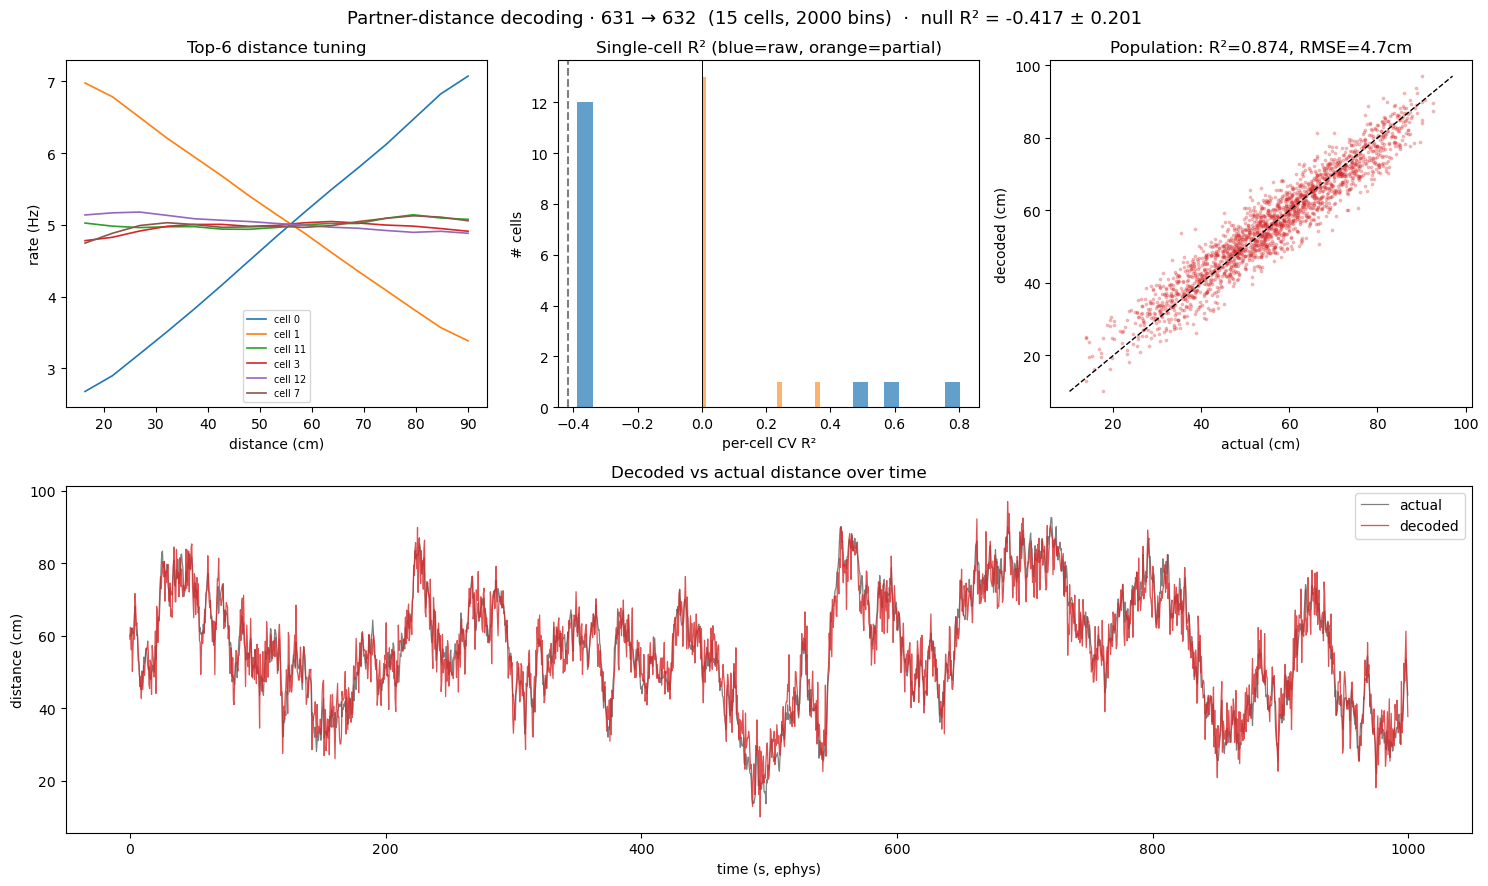

In [18]:
fig = plot_partner_distance_summary(result)
plt.show()

In [ ]:
fig = plot_distance_tuning_curves(result, n_top=8)
plt.show()

In [ ]:
fig = plot_per_cell_r2_distribution(result)   # raw vs partial, with null line
plt.show()

In [ ]:
fig = plot_predicted_vs_actual_scatter(result)
plt.show()
fig = plot_predicted_vs_actual_timeseries(result)
plt.show()

## 3b. When linear ridge breaks down — bump-shaped distance tuning

The cells above are (anti-)*linear* in distance, so linear ridge recovers them
well. Real distance cells are often **bump-shaped**: a cell fires maximally at a
preferred distance and falls off on either side (a "place field" in distance
space). Such a cell has near-zero *linear* correlation with distance, so ridge
throws away exactly that structure — which is a common reason population R² on
real data comes out **negative**.

Below we plant a population of bump-tuned cells tiling the distance range and
decode it two ways with `decoder="both"`:

- **ridge** — the linear regression (primary result, all the usual keys), and
- **Bayesian** — a Poisson decoder over the distance tuning curves
  (`result["bayesian"]`), the 1-D analogue of `ephys.decode_location`.

We also contrast the **mean-of-fold** R² (today's `cv_r2`) with the **pooled**
out-of-fold R² (`cv_r2_pooled`): on strongly autocorrelated, non-stationary
distance with contiguous folds, a single bad fold can drag the mean far
negative even when the concatenated prediction tracks distance — so the pooled
R² is the more honest summary, and the per-fold spread is the diagnostic.

In [ ]:
# --- Bump-tuned population: a few genuine distance cells among many noise cells.
# Each distance cell peaks at a preferred distance (a "place field" in distance
# space) and is non-monotonic, so its *linear* correlation with distance is weak.
rng_b = np.random.default_rng(1)
bump_centers = np.linspace(25.0, 95.0, 4)        # preferred distances (cm)
width, peak_hz = 7.0, 12.0
lam = np.column_stack([peak_hz * np.exp(-0.5 * ((distance - c) / width) ** 2)
                       for c in bump_centers])    # Poisson rate (Hz) per cell
bump_cells = rng_b.poisson(lam * bin_size_sec) / bin_size_sec   # counts -> Hz
noise_b = 5.0 + rng_b.standard_normal((T, 20))    # 20 non-tuned cells
fr_bump = np.clip(np.column_stack([bump_cells, noise_b]), 0.0, None)

res_b = _analyze(
    fr_bump, distance, nuisance, bin_centers,
    units="cm", focal="631", partner="635",
    alpha=1.0, cv_folds=5, n_distance_bins=25, tuning_smoothing_sigma=1.0,
    null="shuffle", n_shuffles=100,
    decoder="both", nuisance_names=nuisance_names, seed=0,
)

print("RIDGE (linear):")
print(f"  CV R2 (mean-of-fold) : {res_b['cv_r2']:.3f}")
print(f"  CV R2 (pooled OOF)   : {res_b['cv_r2_pooled']:.3f}")
print(f"  per-fold R2 spread   : [{res_b['diagnostics']['r2_fold_min']:.2f}, "
      f"{res_b['diagnostics']['r2_fold_max']:.2f}]")
print(f"  RMSE                 : {res_b['rmse']:.2f} cm")
print(f"  null R2              : {res_b['null_r2']:.3f}   (vs-null {res_b['cv_r2_vs_null_z']:.1f} sigma)")
print()
print("BAYESIAN (Poisson over tuning curves):")
print(f"  pooled R2            : {res_b['bayesian']['cv_r2']:.3f}")
print(f"  median error         : {res_b['bayesian']['median_error']:.2f} cm")
print(f"  null R2              : {res_b['bayesian']['null_r2']:.3f}")
print()
print("The Bayesian decoder exploits the bump-shaped tuning that linear ridge "
      "discards. On real data — noisier, sparser tuning — that gap is often the "
      "difference between a positive and a negative population R2.")

In [ ]:
# Diagnostics: per-fold R2 vs pooled R2 vs the null band.
fig = plot_regression_diagnostics(res_b)
plt.show()

# Bayesian posterior over distance through time, with truth overlaid
# (only available because we ran decoder="both").
fig = plot_distance_posterior(res_b)
plt.show()

## 4. Real-data variant (uncomment when the SMB shares are mounted)

`decode_partner_distance` does the whole thing from animal ids: it loads the
**focal** animal's `KilosortData` plus the session `VideoTrackingData` (which
already contains the partner) and a `DataSyncManager`, then bins the focal's
rates + the focal-partner distance + self-motion nuisance on a common ephys grid
(distance/tracking via `resolve_tracking_on_ephys_clock`), and runs the same
`_analyze`. Only the focal animal needs ephys — the partner contributes a
tracking trajectory only. Distances come back in **cm** when the cohort config
sets `pixels_per_cm`, else in pixels (`result['units']`).

In [ ]:
from analysis.partner_distance.decode_partner_distance import decode_partner_distance

# Only the focal animal needs ephys; the partner contributes a tracking
# trajectory only. decode_partner_distance loads the focal's KilosortData +
# the session tracking + sync, bins everything, and runs the same _analyze.
# decoder="both" adds the Bayesian decoder alongside ridge.
result = decode_partner_distance(
    session_id="20251210",
    focal="631",                 # implanted animal (needs ephys)
    partner="635",               # partner (tracking only)
    config_path=None,            # cohort 7 default
    bin_size=0.5, smoothing_sigma_sec=0.25,
    alpha=1.0, cv_folds=5, null="shuffle", n_shuffles=100,
    decoder="both",
)
print("RIDGE   mean-fold R2:", round(result["cv_r2"], 3),
      "| pooled:", round(result.get("cv_r2_pooled", float("nan")), 3),
      "| vs-null:", round(result.get("cv_r2_vs_null_z", float("nan")), 1), "sigma")
if result.get("bayesian") is not None:
    print("BAYES   pooled R2:", round(result["bayesian"]["cv_r2"], 3),
          "| median err:", round(result["bayesian"]["median_error"], 2), result["units"])
plot_partner_distance_summary(result); plt.show()
plot_regression_diagnostics(result); plt.show()
plot_distance_posterior(result); plt.show()

# Equivalent from a shell:
#   python -m analysis.partner_distance.run_partner_distance --session_id 20251216 \
#       --animal_ids 631 635 --bin_size 0.5 --smoothing 0.25 \
#       --decoder both --null shuffle --n_shuffles 100 --output_dir ./results/partner_distance